<a href="https://colab.research.google.com/github/kfafa2018-ux/Computer-Vision/blob/main/%5BNotebook_2%5D_Week_7_Building_Blocks_of_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


About the dataset:

In CIFAR-10, there are 60000, 32x32 color images from these 10 classes, with 6000 images from each class. The training dataset contains 50,000 training images and the test dataset contains 10000 test images.
<br><br>
The dataset images are of color images with a (32 x 32) resolution. All the images in the dataset are of shape (32,32,3) where 3 represents the number of channels i.e R-G-B (Red,Green & Blue).


<img src="./imgs/cifar.png" width="800" height="400" align="center">

### <h3 style="background-color:#0071c5;color:white;text-align: center;padding-top: 5px;padding-bottom: 5px;border-radius: 15px 50px;"><strong><centre>Importing Libraries & Packages 📚 </centre></strong></h3>

In [1]:
# getting started with the model
# importing required libraries/packages

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf


# Imports related to different layers that are to be included in CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Dropout
from tensorflow.keras.layers import GlobalMaxPooling2D, MaxPooling2D
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers, optimizers
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import accuracy_score

from PIL import ImageFont

# to ignore unwanted warnings
import warnings
warnings.filterwarnings('ignore')



### <h3 style="background-color:#0071c5;color:white;text-align: center;padding-top: 5px;padding-bottom: 5px;border-radius: 15px 50px;"><strong><centre> Importing & Reading the dataset </centre></strong></h3>

The keras module has inbuilt datasets and cifar-10 is one among them. So we can simply import the dataset from keras

In [2]:
# Importing the CIFAR-10 dataset from Keras
from tensorflow.keras.datasets import cifar10
(X_train, Y_train), (X_test, Y_test) = cifar10.load_data() #dividing the dataset into training and testing sets.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 724s 4us/step


In [3]:
print('X_train Shape: {}'.format(X_train.shape)) # prints the shape of each subset of datset
print('X_test Shape: {}'.format(X_test.shape))
print('Y_train Shape: {}'.format(Y_train.shape))
print('Y_test Shape: {}'.format(Y_test.shape))

X_train Shape: (50000, 32, 32, 3)
X_test Shape: (10000, 32, 32, 3)
Y_train Shape: (50000, 1)
Y_test Shape: (10000, 1)


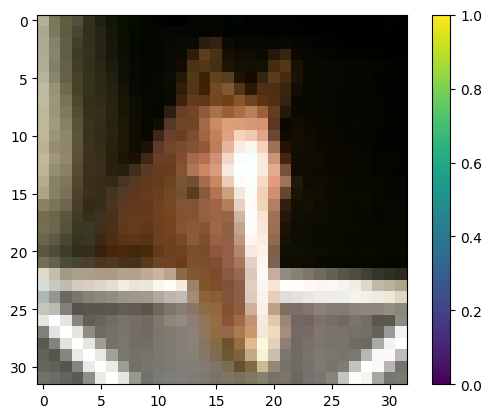

In [15]:
plt.figure()
plt.imshow(X_train[4900]) # displays a random image, Please change the number upto 50000 for a different image
plt.colorbar()
#Before changhing the image to 4900 I saw a bunch of pixels
#The same is true for image 4900 but I can see that the object is a horse

### <h3 style="background-color:#0071c5;color:white;text-align: center;padding-top: 5px;padding-bottom: 5px;border-radius: 15px 50px;"><strong><centre>Normalizing and One-Hot Encoding 🗝</centre></strong></h3>

To lower the pixel values, we must first normalise the data. All of the image pixels are currently in the range of 0–255, and we want them to be in the range of 0 and 1. So we can either divide all the pixel values by 255.0 or use the ‘normalize’ command from keras library. As CIFAR-10 has 10 classes, we are using the ‘to_categorical()’ method to one-hot encode the data.

In [5]:
# Normalizing
X_train = X_train/255
X_test = X_test/255

# One-Hot-Encoding
Y_train_en = to_categorical(Y_train,10)
Y_test_en = to_categorical(Y_test,10)

<hr>

### Some basic layers

1. Conv2D() -> Layer that performs 2D convolutions
2. MaxPooling2D() -> Performs max pooling operation, using the filter we provide
3. Flatten() -> Used to perform flattening before we pass to FC layers
4. Dense() -> The FC layers
5. Dropout() -> Adds dropout to a layer.

### Some basic functions.
1. Sequential() -> Used to initialize a Neural network architecture to which different layers can be added.
2. summary() -> Provides a brief display of CNN architecture
3. compile() -> Compile defines the loss function, the optimizer and the metrics.
4. fit() -> Trains the model using the CNN architecture and training data.
5. evaluate() -> Performs evaluation on test data.

<hr>

### <h3 style="background-color:#0071c5;color:white;text-align: center;padding-top: 5px;padding-bottom: 5px;border-radius: 15px 50px;"><strong><centre>🔨 Building Base Model 🔧</centre></strong></h3>

We are going to build a base model using CNN architecture

In [6]:
# Base Model
Base_Model = Sequential()
Base_Model.add(Conv2D(32,(4,4),input_shape = (32,32,3),activation='relu'))
Base_Model.add(MaxPooling2D(pool_size = (2,2)))
Base_Model.add(Conv2D(32,(4,4),input_shape = (32,32,3),activation='relu'))
Base_Model.add(MaxPooling2D(pool_size = (2,2)))
Base_Model.add(Flatten())
Base_Model.add(Dense(128, activation ='relu'))
Base_Model.add(Dense(10, activation ='softmax'))
Base_Model.compile(loss ='categorical_crossentropy', optimizer ='adam', metrics =['accuracy'])

In [7]:
Base_Model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,802 (475.79 KB)

 Trainable params: 121,802 (475.79 KB)

 Non-trainable params: 0 (0.00 B)

#### Change the number of epochs and observe the changes in accuracy

In [8]:
historyBase = Base_Model.fit(X_train, Y_train_en, epochs = 5, verbose=1,validation_data=(X_test,Y_test_en))



Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 67s 42ms/step - accuracy: 0.4430 - loss: 1.5373 - val_accuracy: 0.5325 - val_loss: 1.2950
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 62s 40ms/step - accuracy: 0.5742 - loss: 1.2055 - val_accuracy: 0.5938 - val_loss: 1.1659
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 84s 41ms/step - accuracy: 0.6231 - loss: 1.0749 - val_accuracy: 0.6225 - val_loss: 1.0744
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 80s 40ms/step - accuracy: 0.6567 - loss: 0.9839 - val_accuracy: 0.6028 - val_loss: 1.1434
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 63s 40ms/step - accuracy: 0.6832 - loss: 0.9094 - val_accuracy: 0.6610 - val_loss: 0.9897


In [9]:
evaluationBase = Base_Model.evaluate(X_test, Y_test_en)
print('Test Accuracy of Base Model: {}'.format(evaluationBase[1]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6610 - loss: 0.9897
Test Accuracy of Base Model: 0.6610000133514404


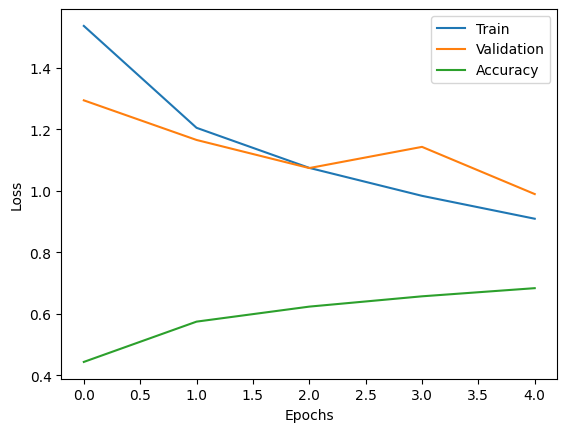

In [10]:
def plotloss(history):
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.plot(history.history['accuracy'])
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation', 'Accuracy'])
    plt.show()
plotloss(historyBase)

When ran for 20 epochs, the accuracy jumps to 86.9% and the testing accuracy reaches 67.12%.

But one key thing to observe is that, the validation loss kept continously increasing which is a sign of overfitting.


### <h3 style="background-color:#0071c5;color:white;text-align: center;padding-top: 5px;padding-bottom: 5px;border-radius: 15px 50px;"><strong><centre>Adding Dropouts</centre></strong></h3>

In [11]:
# Model_1 with Dropouts
DropoutModel = Sequential()
DropoutModel.add(Conv2D(64,(4,4),input_shape=(32,32,3),activation='relu'))
DropoutModel.add(MaxPooling2D(pool_size=(2,2)))
DropoutModel.add(Dropout(0.5))
DropoutModel.add(Conv2D(64,(4,4),input_shape=(32,32,3),activation='relu'))
DropoutModel.add(MaxPooling2D(pool_size=(2,2)))
DropoutModel.add(Dropout(0.25))
DropoutModel.add(Flatten())
DropoutModel.add(Dense(256,activation='relu'))
DropoutModel.add(Dense(10,activation='softmax'))
DropoutModel.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

DropoutModel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 29, 29, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 481,162 (1.84 MB)

 Trainable params: 481,162 (1.84 MB)

 Non-trainable params: 0 (0.00 B)

#### Change the value of epochs and the value of Dropout in the above model, observe the changes in accuracy and loss.

In [12]:
DropoutHistory = DropoutModel.fit(X_train, Y_train_en, epochs = 5, verbose=1, validation_data=(X_test,Y_test_en))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 164s 104ms/step - accuracy: 0.4274 - loss: 1.5723 - val_accuracy: 0.5466 - val_loss: 1.2766
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 199s 102ms/step - accuracy: 0.5450 - loss: 1.2784 - val_accuracy: 0.5922 - val_loss: 1.1746
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 159s 101ms/step - accuracy: 0.5949 - loss: 1.1513 - val_accuracy: 0.6294 - val_loss: 1.0593
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 161s 103ms/step - accuracy: 0.6262 - loss: 1.0654 - val_accuracy: 0.6453 - val_loss: 1.0178
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 199s 101ms/step - accuracy: 0.6522 - loss: 0.9930 - val_accuracy: 0.6672 - val_loss: 0.9590


In [13]:
Dropevaluation = DropoutModel.evaluate(X_test, Y_test_en)
print('Test Accuracy of DropoutModel(with Dropouts): {}'.format(Dropevaluation[1]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.6672 - loss: 0.9590
Test Accuracy of DropoutModel(with Dropouts): 0.6672000288963318


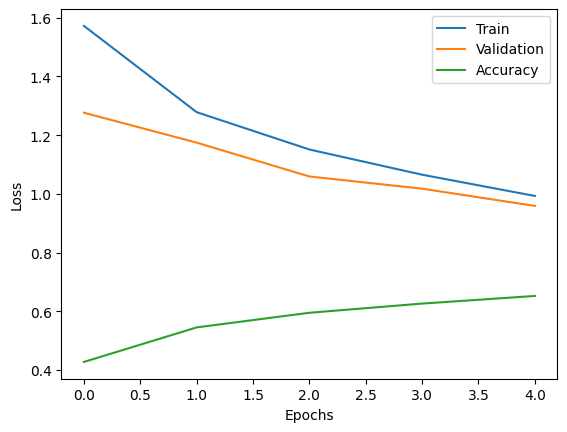

In [14]:
def plotloss(history_1):
    plt.plot(history_1.history['loss'])
    plt.plot(history_1.history['val_loss'])
    plt.plot(history_1.history['accuracy'])
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation', 'Accuracy'])
    plt.show()
plotloss(DropoutHistory)

When the model with dropout has ran for 30 epochs, the validation accuracy increased from 67% to 71% and also the reduction in models validation loss can be clearly observed.

